# Phase 3b: Why did the Kalman filter underperform?

In Phase 3, ridge regression (400 ms of spike history) reached held-out R² = 0.61. The Kalman filter reached 0.40 on the same 700 test bins. This notebook tests two of the possible explanations:

1. **Too many parameters in the neural noise model.** The original filter estimates how every pair of the 142 neurons varies together: about 10,000 numbers from roughly 2,800 training bins. If that is the problem, a simpler noise model should do better.
2. **Lag at the edge of the range tried.** Phase 3 chose a 160 ms lag, the longest it tested. Here lags run from 0 to 280 ms.

**What would support each explanation:**
- If a simpler noise model scores clearly higher than the original "full" model, explanation 1 is supported.
- If the best lag now falls inside the range rather than at its edge, the lag question is settled.

Settings are chosen by cross-validation on the 80 training trials only. Each model's settings are then scored once on the 20 test trials, the same ones as in Phases 2 and 3.

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import r2_score
from sklearn.model_selection import KFold

sys.path.insert(0, os.path.abspath(".."))
from src.data import BIN_MS, load_dataset, get_trials, build_sequences
from src.decoders import KalmanDecoder

DATA_PATH = "../data/000140/sub-Jenkins/"
NOISE_MODELS = ["full", "diagonal", "shrinkage"]
LAGS_MS = [0, 40, 80, 120, 160, 200, 240, 280]
WINDOWS = [1, 3, 5, 7]                       # in 20 ms bins: 20, 60, 100, 140 ms
MARGIN_MS = 400                              # extra data before each window (covers lag + window)
RIDGE_PHASE3 = {"R² x": 0.686, "R² y": 0.525, "R² mean": 0.606}   # Phase 3 ridge, same 700 test bins
os.makedirs("../figures", exist_ok=True)

## 1. Load the data and reuse the same split

In [2]:
dataset = load_dataset(DATA_PATH)
trials = get_trials(dataset, history_ms=MARGIN_MS)

trial_ids = np.unique(trials["trial_id"])
rng = np.random.default_rng(0)                          # same seed as Phases 2 and 3
test_ids = rng.choice(trial_ids, size=20, replace=False)
train_ids = np.setdiff1d(trial_ids, test_ids)
print(len(train_ids), "training trials |", len(test_ids), "test trials")

80 training trials | 20 test trials


## 2. Three ways to model the neural noise

The Kalman filter's neural model predicts each neuron's spike count from the hand state. Its **noise model** (Q) describes how far the actual counts typically stray from those predictions. The filter uses Q to decide how much to trust each new set of spikes.

- **Full (original):** estimates every neuron's variance *and* how every pair of neurons varies together, about 10,000 numbers. This is flexible, but noisy when training data is limited.
- **Diagonal:** estimates only each neuron's own variance (142 numbers) and treats neurons as independent. Much simpler, but it ignores shared fluctuations.
- **Shrinkage (Ledoit-Wolf):** starts from the full estimate and pulls it toward a simpler one. The amount of pulling is chosen automatically from the data. This is a middle ground.

The next cell tries every combination of noise model, lag, and spike window with 5-fold cross-validation on the training trials. It takes a few minutes (96 combinations, each cross-validated 5 ways).

In [3]:
def kalman_velocity_r2(model, seqs, ids):
    # R² for x and y velocity, pooled over the given trials
    true, pred = [], []
    for tid in ids:
        s = seqs[tid]
        est = model.predict(s["Z"])
        known = ~np.isnan(s["X"]).any(axis=1)
        true.append(s["X"][known, 2:4]); pred.append(est[known, 2:4])
    return r2_score(np.vstack(true), np.vstack(pred), multioutput="raw_values")

folds = list(KFold(n_splits=5, shuffle=True, random_state=0).split(train_ids))
seq_cache, rows = {}, []
for lag in LAGS_MS:
    for w in WINDOWS:
        seqs = {s["trial_id"]: s for s in build_sequences(trials, lag, w)}
        seq_cache[(lag, w)] = seqs
        for noise in NOISE_MODELS:
            scores = [kalman_velocity_r2(KalmanDecoder(noise=noise).fit([seqs[i] for i in train_ids[tr]]),
                                         seqs, train_ids[va]).mean()
                      for tr, va in folds]
            rows.append({"noise": noise, "lag_ms": lag, "window_ms": w * BIN_MS, "cv_r2": np.mean(scores)})
cv = pd.DataFrame(rows)

for noise in NOISE_MODELS:
    print(f"\n{noise} noise model: cross-validated R² (rows: lag in ms, columns: spike window in ms)")
    print(cv[cv["noise"] == noise].pivot(index="lag_ms", columns="window_ms", values="cv_r2").round(3))


full noise model: cross-validated R² (rows: lag in ms, columns: spike window in ms)
window_ms    20     60     100    140
lag_ms                               
0          0.317  0.337  0.318  0.315
40         0.355  0.375  0.371  0.374
80         0.403  0.422  0.413  0.411
120        0.434  0.442  0.437  0.422
160        0.442  0.457  0.431  0.390
200        0.426  0.416  0.351  0.276
240        0.362  0.315  0.232  0.149
280        0.283  0.230  0.149  0.068

diagonal noise model: cross-validated R² (rows: lag in ms, columns: spike window in ms)
window_ms    20     60     100    140
lag_ms                               
0          0.280  0.257  0.248  0.247
40         0.320  0.303  0.306  0.320
80         0.367  0.363  0.376  0.395
120        0.406  0.414  0.426  0.421
160        0.424  0.431  0.413  0.378
200        0.402  0.376  0.330  0.264
240        0.329  0.273  0.199  0.120
280        0.242  0.153  0.070 -0.006

shrinkage noise model: cross-validated R² (rows: lag in ms, colum

## 3. Score each noise model's best settings on the test trials

In [4]:
results = []
for noise in NOISE_MODELS:
    best = cv[cv["noise"] == noise].sort_values("cv_r2", ascending=False).iloc[0]
    lag, w = int(best["lag_ms"]), int(best["window_ms"]) // BIN_MS
    seqs = seq_cache[(lag, w)]
    model = KalmanDecoder(noise=noise).fit([seqs[i] for i in train_ids])
    r2x, r2y = kalman_velocity_r2(model, seqs, test_ids)
    n_bins = sum((~np.isnan(seqs[t]["X"]).any(axis=1)).sum() for t in test_ids)
    results.append({"decoder": f"Kalman, {noise} noise", "lag_ms": lag, "window_ms": w * BIN_MS,
                    "cv_r2": best["cv_r2"], "R² x": r2x, "R² y": r2y, "R² mean": (r2x + r2y) / 2,
                    "test_bins": n_bins})
results.append({"decoder": "Ridge, 400 ms history (Phase 3)", **RIDGE_PHASE3})
summary = pd.DataFrame(results)
for col in ["lag_ms", "window_ms", "test_bins"]:
    summary[col] = summary[col].astype("Int64")
print(summary.round(3).to_string(index=False))

edge = summary.loc[summary["lag_ms"] == max(LAGS_MS), "decoder"].tolist()
if edge:
    print("\nnote: the longest lag tried (", max(LAGS_MS), "ms) was chosen for:", ", ".join(edge))

                        decoder  lag_ms  window_ms  cv_r2  R² x  R² y  R² mean  test_bins
             Kalman, full noise     160         60  0.457 0.506 0.294    0.400        700
         Kalman, diagonal noise     160         60  0.431 0.500 0.145    0.323        700
        Kalman, shrinkage noise     160         60  0.467 0.508 0.301    0.405        700
Ridge, 400 ms history (Phase 3)    <NA>       <NA>    NaN 0.686 0.525    0.606       <NA>


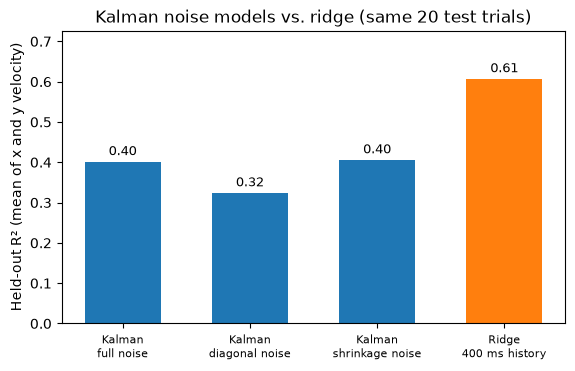

In [5]:
# Figure 10: held-out R² (mean of x and y) for each Kalman noise model, next to the ridge decoder
plot = summary.copy()
plot["label"] = [d.replace("Kalman, ", "Kalman\n").replace(" noise", " noise") if d.startswith("Kalman")
                 else "Ridge\n400 ms history" for d in plot["decoder"]]
colors = ["tab:blue" if d.startswith("Kalman") else "tab:orange" for d in plot["decoder"]]
fig, ax = plt.subplots(figsize=(6.5, 3.8))
bars = ax.bar(plot["label"], plot["R² mean"], color=colors, width=0.6)
for bar, v in zip(bars, plot["R² mean"]):
    ax.text(bar.get_x() + bar.get_width() / 2, v + 0.01, f"{v:.2f}", ha="center", va="bottom", fontsize=9)
ax.set_ylabel("Held-out R² (mean of x and y velocity)")
ax.set_title("Kalman noise models vs. ridge (same 20 test trials)")
ax.set_ylim(0, min(1.0, plot["R² mean"].max() + 0.12))
ax.tick_params(axis="x", labelsize=8)
plt.savefig("../figures/10_kalman_noise_models.png", dpi=150, bbox_inches="tight")

## Results to record

**How to read the table:**
- Compare the **diagonal** and **shrinkage** rows with the **full** row. A clear gain, for example 0.05 or more in mean R², supports the "too many parameters" explanation. No gain means that explanation is unlikely.
- Check whether each model's chosen lag sits inside the 0–280 ms range or at its top edge.
- Compare the best Kalman row with ridge. If ridge still wins, the remaining explanations, a movement model too simple for reaches and planning activity read as movement, become the leading candidates. A recurrent neural network (Phase 4) can learn richer movement dynamics and addresses both.

In [6]:
best_k = summary[summary["decoder"].str.startswith("Kalman")].sort_values("R² mean", ascending=False).iloc[0]
full_k = summary[summary["decoder"] == "Kalman, full noise"].iloc[0]
print(f"Best Kalman variant: {best_k['decoder']} (lag {int(best_k['lag_ms'])} ms, {int(best_k['window_ms'])} ms window): "
      f"held-out R² = {best_k['R² mean']:.2f} (x = {best_k['R² x']:.2f}, y = {best_k['R² y']:.2f})")
print(f"Original full-noise Kalman: held-out R² = {full_k['R² mean']:.2f} | Ridge (Phase 3): {RIDGE_PHASE3['R² mean']:.2f}")

Best Kalman variant: Kalman, shrinkage noise (lag 160 ms, 60 ms window): held-out R² = 0.40 (x = 0.51, y = 0.30)
Original full-noise Kalman: held-out R² = 0.40 | Ridge (Phase 3): 0.61
